# Evaluasi Model Klasifikasi Framework Web

Jalankan *cell* di bawah ini. Anda akan diminta untuk **mengunggah (upload)** file `dataset_train.csv` dan `dataset_test.csv` melalui tombol *Choose Files* yang akan muncul.

In [3]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Menyediakan tombol trigger untuk upload file di Google Colab
from google.colab import files
print("Silakan klik 'Choose Files' dan pilih dataset_train.csv serta dataset_test.csv secara bersamaan:")
uploaded = files.upload()

# Deteksi otomatis mana file train dan test dari nama file yang diunggah
nama_file_diunggah = list(uploaded.keys())

try:
    train_file = next(f for f in nama_file_diunggah if 'train' in f.lower())
    test_file = next(f for f in nama_file_diunggah if 'test' in f.lower())
except StopIteration:
    raise ValueError("Error: Harap unggah KEDUA file (dataset_train.csv dan dataset_test.csv) secara bersamaan!")

# Memuat dataset ke dalam Pandas DataFrame
df_train = pd.read_csv(io.BytesIO(uploaded[train_file]))
df_test = pd.read_csv(io.BytesIO(uploaded[test_file]))

print(f"\nBerhasil memuat data training dari: {train_file}")
print(f"Berhasil memuat data testing dari: {test_file}")

# Memisahkan fitur dan target
X_train = df_train.drop(columns=['Y_framework', 'repository'])
y_train = df_train['Y_framework']

X_test = df_test.drop(columns=['Y_framework', 'repository'])
y_test = df_test['Y_framework']

# Mapping Framework
framework_mapping = {
    1: 'Django', 2: 'FastAPI', 3: 'Ruby on Rails',
    4: 'Next.js', 5: 'Flask', 6: 'Spring Boot',
    7: 'Laravel', 8: 'Symfony', 9: 'Express.js'
}
labels = [framework_mapping[i] for i in range(1, 10)]

print("\nDataset Training Shape:", X_train.shape)
print("Dataset Testing Shape:", X_test.shape)
df_train.head()

Silakan klik 'Choose Files' dan pilih dataset_train.csv serta dataset_test.csv secara bersamaan:


Saving dataset_test.csv to dataset_test.csv
Saving dataset_train.csv to dataset_train (2).csv

Berhasil memuat data training dari: dataset_train (2).csv
Berhasil memuat data testing dari: dataset_test.csv

Dataset Training Shape: (720, 10)
Dataset Testing Shape: (180, 10)


,X1_application_type,X2_primary_language,X3_database,X4_has_docker,X5_has_ci_cd,X6_has_tests,X7_monorepo,X8_contributors,X9_pengguna,X10_active_weeks,Y_framework,repository
0,5,2,4,1,1,1,0,4,3,1,7,Paymenter/Paymenter
1,1,1,1,0,1,1,0,4,3,1,1,dj-stripe/dj-stripe
2,1,2,0,0,1,1,0,4,4,3,7,koel/koel
3,2,1,3,1,1,1,0,2,2,1,2,baoliay2008/lccn_predictor
4,1,2,0,1,0,1,0,4,4,3,7,BookStackApp/BookStack


In [4]:
# Melatih Model
print("Melatih model Random Forest...")
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

# Melakukan Prediksi
y_pred = rf.predict(X_test)
print("Selesai melatih dan melakukan prediksi pada data testing!")

Melatih model Random Forest...
Selesai melatih dan melakukan prediksi pada data testing!


## 1. Metrik Evaluasi Utama (Tabel)

In [5]:
accuracy = accuracy_score(y_test, y_pred)
macro_precision = precision_score(y_test, y_pred, average='macro')
macro_recall = recall_score(y_test, y_pred, average='macro')
macro_f1 = f1_score(y_test, y_pred, average='macro')

metrics_df = pd.DataFrame({
    'Metrik': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score'],
    'Nilai': [accuracy, macro_precision, macro_recall, macro_f1]
})

display(metrics_df)

,Metrik,Nilai
0,Accuracy,0.872222
1,Macro Precision,0.879351
2,Macro Recall,0.872222
3,Macro F1-Score,0.868077


## 2. Classification Report (Tabel Kinerja per Kelas)

In [6]:
report_dict = classification_report(y_test, y_pred, target_names=labels, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()

display(report_df)

,precision,recall,f1-score,support
Django,0.714286,0.500000,0.588235,20.000000
FastAPI,0.739130,0.850000,0.790698,20.000000
Ruby on Rails,1.000000,1.000000,1.000000,20.000000
Next.js,0.952381,1.000000,0.975610,20.000000
Flask,0.739130,0.850000,0.790698,20.000000
Spring Boot,1.000000,1.000000,1.000000,20.000000
Laravel,1.000000,0.700000,0.823529,20.000000
Symfony,0.769231,1.000000,0.869565,20.000000
Express.js,1.000000,0.950000,0.974359,20.000000
accuracy,0.872222,0.872222,0.872222,0.872222


## 3. Confusion Matrix

Tabel Confusion Matrix:


Predicted Framework,Django,FastAPI,Ruby on Rails,Next.js,Flask,Spring Boot,Laravel,Symfony,Express.js
Actual Framework,,,,,,,,,
Django,10,6,0,0,4,0,0,0,0
FastAPI,1,17,0,0,2,0,0,0,0
Ruby on Rails,0,0,20,0,0,0,0,0,0
Next.js,0,0,0,20,0,0,0,0,0
Flask,3,0,0,0,17,0,0,0,0
Spring Boot,0,0,0,0,0,20,0,0,0
Laravel,0,0,0,0,0,0,14,6,0
Symfony,0,0,0,0,0,0,0,20,0
Express.js,0,0,0,1,0,0,0,0,19



Grafik Heatmap:


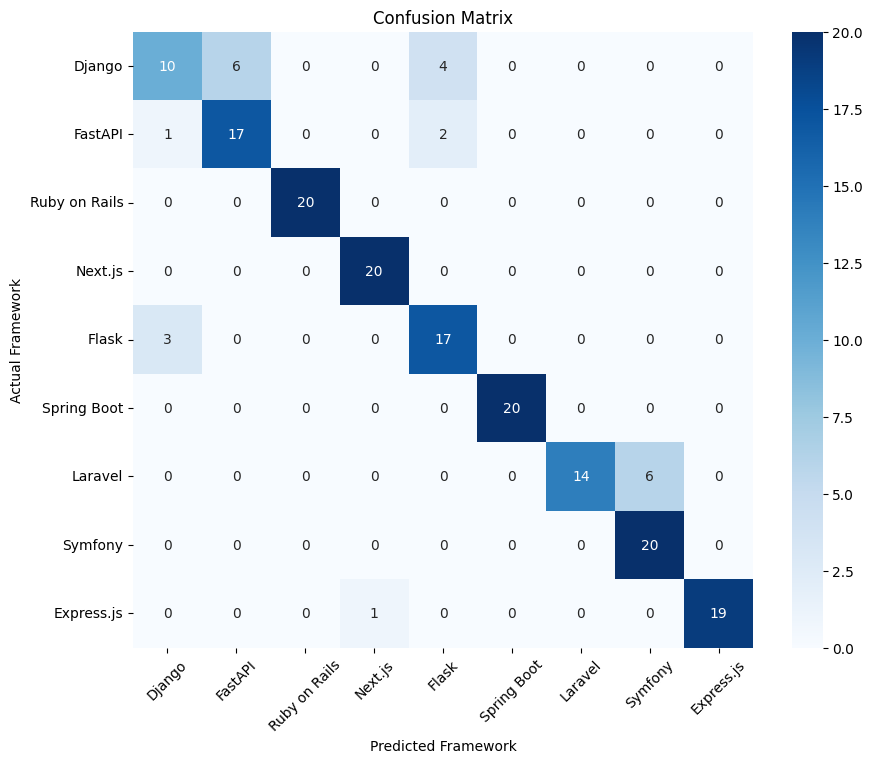

In [7]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
cm_df.index.name = 'Actual Framework'
cm_df.columns.name = 'Predicted Framework'

print("Tabel Confusion Matrix:")
display(cm_df)

print("\nGrafik Heatmap:")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Framework')
plt.ylabel('Actual Framework')
plt.xticks(rotation=45)
plt.show()

## 4. Feature Importance (Karakteristik Paling Berpengaruh)

Tabel Feature Importance:


,Karakteristik Proyek,Tingkat Kepentingan
1,primary_language,0.467261
0,application_type,0.110345
2,database,0.094518
8,pengguna,0.093026
5,has_tests,0.053126
7,contributors,0.051769
3,has_docker,0.040730
9,active_weeks,0.030808
6,monorepo,0.030388
4,has_ci_cd,0.028030



Grafik Feature Importance:


/tmp/ipykernel_2557/1224091696.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Tingkat Kepentingan', y='Karakteristik Proyek', data=importance_df, palette='viridis')


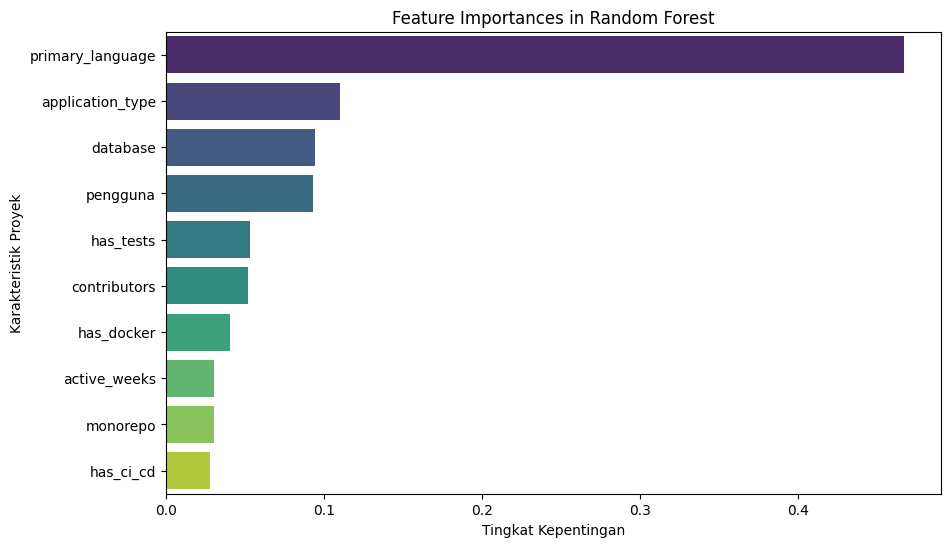

In [8]:
importances = rf.feature_importances_
features = X_train.columns
clean_features = [f.split('_', 1)[1] if '_' in f else f for f in features]

importance_df = pd.DataFrame({
    'Karakteristik Proyek': clean_features,
    'Tingkat Kepentingan': importances
}).sort_values(by='Tingkat Kepentingan', ascending=False)

print("Tabel Feature Importance:")
display(importance_df)

print("\nGrafik Feature Importance:")
plt.figure(figsize=(10, 6))
sns.barplot(x='Tingkat Kepentingan', y='Karakteristik Proyek', data=importance_df, palette='viridis')
plt.title('Feature Importances in Random Forest')
plt.show()